In [1]:
# import required modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=FutureWarning)

colors = [
    "darkred",
    "navy",
    "darkgreen",
    "goldenrod",
    "deeppink",
    "darkorange",
    "firebrick",
    "indigo",
    "teal",
    "darkmagenta",
    "saddlebrown",
    'gray',
    'darkblue'
]

In [2]:
base_path = os.path.dirname(os.path.dirname(os.getcwd()))
base_path

'd:\\Codes\\Projects\\BusInsp\\Business_Inspector'

In [3]:
df = pd.read_csv(rf'{base_path}\datasets\online_retail_ii.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      525461 non-null  object 
 1   StockCode    525461 non-null  object 
 2   Description  522533 non-null  object 
 3   Quantity     525461 non-null  int64  
 4   InvoiceDate  525461 non-null  object 
 5   Price        525461 non-null  float64
 6   Customer ID  417534 non-null  float64
 7   Country      525461 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.1+ MB


In [5]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df.shape

(525461, 8)

In [7]:
# Checking for the time duration of the dataset

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.InvoiceDate.max(), df.InvoiceDate.min()

(Timestamp('2010-12-09 20:01:00'), Timestamp('2009-12-01 07:45:00'))

## Missing Values

In [8]:
print('Missing Value Count:')
print(df.isnull().sum().sort_values(ascending=False), '\n')

print('Missing Values Proportion:')
print(df.isnull().sum().sort_values(ascending=False)/df.shape[0])

Missing Value Count:
Customer ID    107927
Description      2928
Invoice             0
StockCode           0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64 

Missing Values Proportion:
Customer ID    0.205395
Description    0.005572
Invoice        0.000000
StockCode      0.000000
Quantity       0.000000
InvoiceDate    0.000000
Price          0.000000
Country        0.000000
dtype: float64


In [9]:
# drop nan values

print(f'Number of rows before droping nan: {df.shape[0]}\n')
df.dropna(inplace=True)
print(df.isnull().sum().sort_values(ascending=False), '\n')
print(f'Number of rows after droping nan: {df.shape[0]}')

Number of rows before droping nan: 525461

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64 

Number of rows after droping nan: 417534


# Statistic Summary and Outliers with Visuals

In [10]:
df.describe([0.01, 0.05, .10, .20, .30, .50, .70, .80, .90])

,Quantity,InvoiceDate,Price,Customer ID
count,417534.000000,417534,417534.000000,417534.000000
mean,12.758815,2010-07-01 01:12:19.787609856,3.887547,15360.645478
min,-9360.000000,2009-12-01 07:45:00,0.000000,12346.000000
1%,-2.000000,2009-12-02 15:04:00,0.290000,12435.000000
5%,1.000000,2009-12-13 12:42:00,0.420000,12725.000000
10%,1.000000,2010-01-18 14:49:00,0.650000,13042.000000
20%,1.000000,2010-03-05 09:09:00,0.850000,13624.000000
30%,2.000000,2010-04-19 12:45:00,1.250000,14256.000000
50%,4.000000,2010-07-08 19:12:00,1.950000,15311.000000
70%,10.000000,2010-10-03 10:51:00,2.950000,16549.000000


There are some negative values, which shows the returned items.

Invoice having 'C' in it are the returned entries

In [11]:
df = df[~df['Invoice'].str.contains('C', na=False)]

In [12]:
des = df.describe([.1, .2, .3, .5, .6, .7, .9])
des

,Quantity,InvoiceDate,Price,Customer ID
count,407695.000000,407695,407695.000000,407695.000000
mean,13.586686,2010-07-01 10:10:10.782177792,3.294188,15368.504107
min,1.000000,2009-12-01 07:45:00,0.000000,12346.000000
10%,1.000000,2010-01-19 11:01:00,0.650000,13044.000000
20%,2.000000,2010-03-05 11:31:00,0.850000,13635.000000
30%,2.000000,2010-04-19 14:09:00,1.250000,14274.000000
50%,5.000000,2010-07-09 15:46:00,1.950000,15321.000000
60%,6.000000,2010-08-25 15:58:00,2.550000,15967.000000
70%,12.000000,2010-10-03 12:00:00,2.950000,16549.000000
90%,24.000000,2010-11-18 10:37:00,6.750000,17706.000000


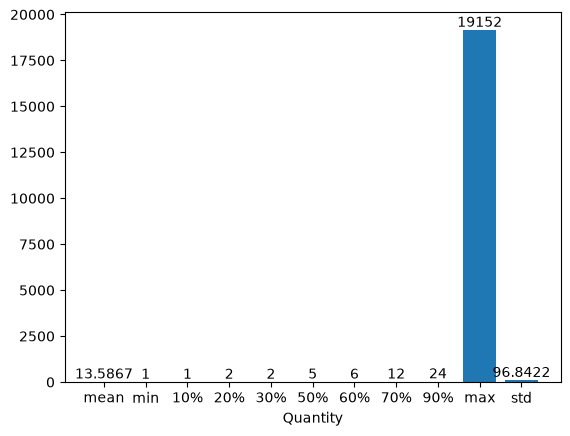

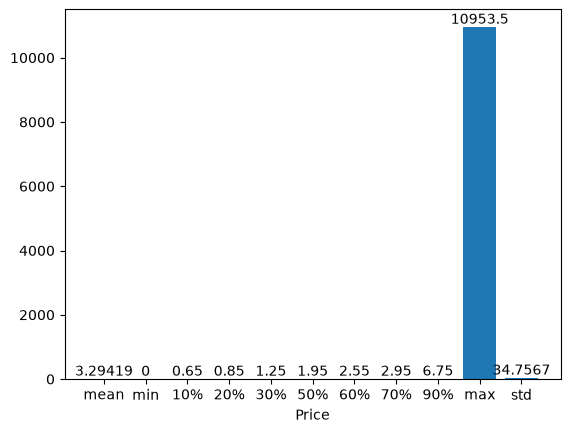

In [13]:
plt.Figure(figsize=(7, 5))
bar_plot = plt.bar(des.index[1:], des['Quantity'][1:])
plt.bar_label(bar_plot)
plt.xlabel('Quantity')
plt.show()

plt.Figure(figsize=(7, 5))
bar_plot = plt.bar(des.index[1:], des['Price'][1:])
plt.bar_label(bar_plot)
plt.xlabel('Price')
plt.show()

<Axes: >

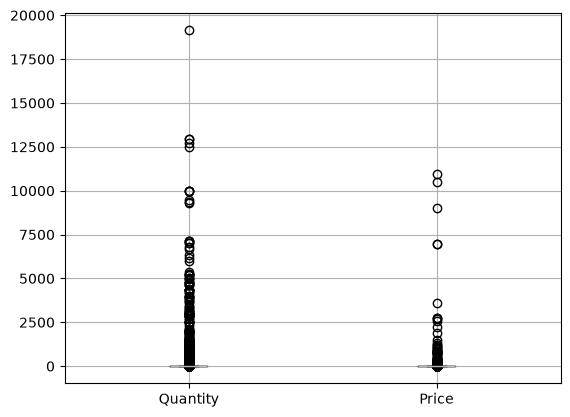

In [14]:
df[['Quantity', 'Price']].boxplot()

In [15]:
country_count = df['Country'].value_counts()
country_count

Country
United Kingdom          370951
EIRE                      8507
Germany                   7661
France                    5470
Netherlands               2730
Spain                     1235
Switzerland               1170
Belgium                   1038
Portugal                   984
Sweden                     868
Channel Islands            821
Italy                      710
Australia                  630
Cyprus                     541
Austria                    524
Greece                     512
Denmark                    418
Norway                     365
Finland                    347
United Arab Emirates       315
Unspecified                277
USA                        230
Poland                     182
Malta                      170
Japan                      164
Lithuania                  154
Singapore                  117
Canada                      77
Thailand                    76
Israel                      74
Iceland                     71
RSA                         65


In [16]:
fig = px.pie(names=country_count.index[1:], values=country_count.values[1:])
#fig.update_traces(textinfo='none')
fig.update_traces(
    textinfo="none",
    hovertemplate=(
        "Country: <b>%{label}</b><br>"
        "Customer Count: %{value}<br>"
        "Percentage: %{percent}"
        "<extra></extra>"
    )
)
fig.show()

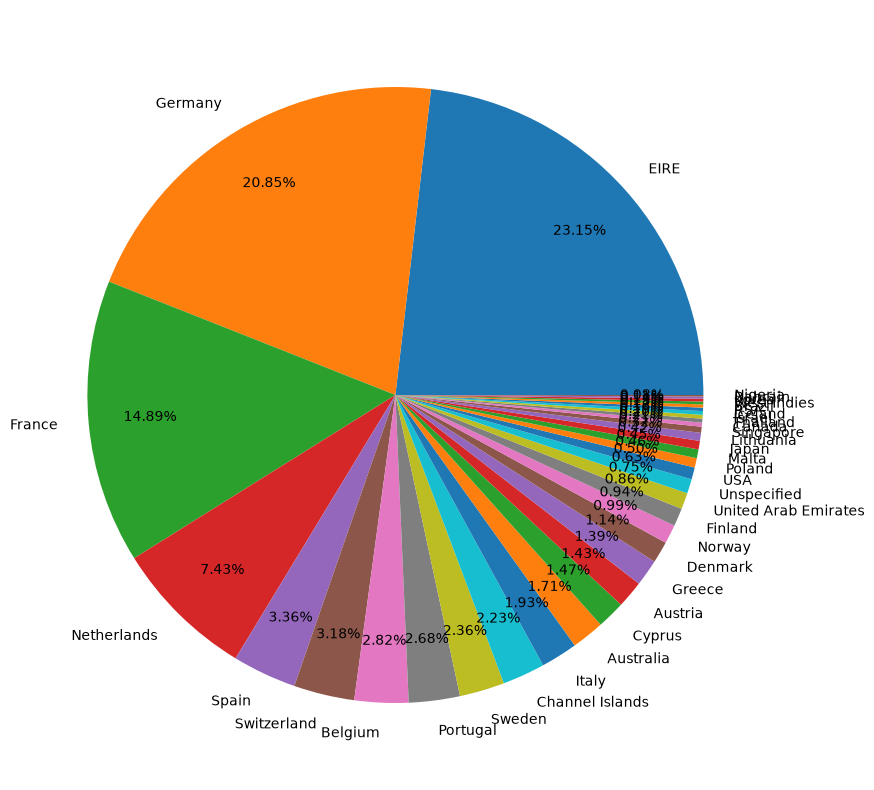

In [17]:
plt.figure(figsize=(10,10))
labels = country_count.index[1:]
fig = plt.pie(x=country_count[1:], labels=labels, autopct='%.2f%%', pctdistance=0.8)
plt.show()

In [18]:
from sklearn.cluster import DBSCAN

In [19]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [20]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [24]:
df['Amount'] = df['Price']*df['Quantity']
df['Customer ID'] = df['Customer ID'].astype('int')

In [ ]:
x_train = df['Amount', 'Customer ID']

In [21]:
model = DBSCAN(eps=1, min_samples=5, n_jobs=-1)
model.fit(df['Customer ID',df[df['Price']*df['Quantity']]])

KeyError: "None of [Index([              83.4,               81.0,               81.0,\n       100.80000000000001,               30.0, 39.599999999999994,\n                     30.0,               59.5, 30.599999999999998,\n                     45.0,\n       ...\n                      4.2,                4.2,               5.96,\n                      7.5,                2.5,                5.9,\n                     3.75,               3.75,                7.5,\n                      3.9],\n      dtype='float64', length=407695)] are in the [columns]"